# Klike.Ai - Fase 2: Desafio Técnico
## Anna Luiza Braga de Albuquerque
---

## Sumário

1. [Introdução e carregamento dos dados](#introducao)
2. [Parte 1 — Análise Exploratória (EDA)](#parte-1-analise-exploratoria)
3. [Parte 2 — Modelagem](#parte-2-modelagem)
4. [Parte 3 — Recommendations Engine](#parte-3-recommendations-engine)

A Parte 4 — Visão de Produto está no README.md.

---
<a id="introducao"></a>
## Introdução e carregamento dos dados

In [1]:
#importando as bibliotecas e a base de dados
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("klike_challenge_dataset.csv")

#análise inicial do problema
print("Dimensão da base de dados: ", df.shape, '\n')
display(df.head())

Dimensão da base de dados:  (500, 26) 



,campaign_id,date,platform,category,objective,target_audience_age,is_retargeting,video_duration_s,format,has_subtitle,...,clicks,ctr,cpc,spend,conversions,revenue,roas,avg_watch_time_s,engagement_rate,klike_score
0,KLK-0001,2024-01-01,Meta,Branding,awareness,18-24,False,NaN,vertical,True,...,5882,0.0390,0.82,4823.24,48,0.00,0.00,3.9,0.0446,63.6
1,KLK-0002,2024-03-22,LinkedIn,App Install,traffic,25-34,False,NaN,horizontal,True,...,493,0.0664,3.54,1745.22,34,NaN,0.16,6.4,0.0217,70.0
2,KLK-0003,2024-05-04,TikTok,SaaS,traffic,25-34,False,8.0,vertical,True,...,15069,0.0780,0.38,5726.22,492,51053.44,8.92,8.0,0.1000,99.1
3,KLK-0004,2024-12-27,TikTok,Lead Gen,engagement,25-34,False,27.0,quadrado,False,...,601,0.0925,0.71,426.71,19,1113.78,2.61,20.3,0.0414,74.9
4,KLK-0005,2024-07-10,Meta,Branding,engagement,25-34,False,34.0,vertical,True,...,2355,0.0369,0.38,894.90,13,0.00,0.00,34.0,0.0184,77.9


---
<a id="parte-1-analise-exploratoria"></a>
## Parte 1 — Análise Exploratória (EDA)
## 1.1. Perfil geral e qualidade dos dados
Nesta seção, analisa-se as inconsistências presentes na base de dados,  seja por ausência de dados, erro na classificação de variáveis, duplicatas, distribuições ou métrica.

Foram identificados valores faltantes em 7 das 26 colunas. Eles foram mantidos nesta etapa para evitar perda de informações. Não foram encontradas duplicatas nem categorias inesperadas nas variáveis qualitativas. Além disso, o tipo de categorias (com exceção da data e presença/ausência de legenda) está correto. Nas variáveis numéricas, o `describe()` revela diferenças expressivas entre o percentil 99 e o valor máximo em algumas colunas. Esses valores também foram mantidos, pois ainda não há evidência de que sejam erros.

### 1.1.1 Dados faltantes
Há **dados faltantes em 7 das 26 colunas**, sendo elas: `has_subtitle`, `video_duration_s`, `music_voice_ratio`, `engagement_rate`, `cpc`, `avg_watch_time_s` e `revenue`.

A coluna com maior número de dados faltantes, `has_subtitle`, representa 9,2% dos dados. Assim, a simples exclusão de linhas ou colunas descartaria informações potencialmente úteis. Portanto, as variáveis serão mantidas e o tratamento será definido com base no significado das variáveis.

In [2]:
#Quantos dados faltam em cada coluna, começando pela coluna com maior número de dados faltantes:
df.isna().sum().sort_values(ascending=False)

has_subtitle           46
video_duration_s       39
music_voice_ratio      38
engagement_rate        32
cpc                    28
avg_watch_time_s       27
revenue                25
campaign_id             0
roas                    0
conversions             0
spend                   0
ctr                     0
clicks                  0
impressions             0
text_density            0
date                    0
has_face                0
has_hook                0
has_cta                 0
format                  0
is_retargeting          0
target_audience_age     0
objective               0
category                0
platform                0
klike_score             0
dtype: int64

### 1.1.2 Tipos incorretos
Os **tipos de dados estão, majoritariamente, conceitualmente corretos**. Os únicos problemas estão nas variáveis `date`, que está armazenada como *object* e deveria estar como *datetime* caso quiséssemos comparar os Klike Scores em relação ao tempo, e `has_subtitle`, que está armazenada como *object* devido a presença de dados faltantes, porém é conceitualmente *booleana*.

In [3]:
df.dtypes

campaign_id             object
date                    object
platform                object
category                object
objective               object
target_audience_age     object
is_retargeting            bool
video_duration_s       float64
format                  object
has_subtitle            object
has_cta                   bool
has_hook                  bool
has_face                  bool
text_density            object
music_voice_ratio      float64
impressions              int64
clicks                   int64
ctr                    float64
cpc                    float64
spend                  float64
conversions              int64
revenue                float64
roas                   float64
avg_watch_time_s       float64
engagement_rate        float64
klike_score            float64
dtype: object

### 1.1.3. Dados inconsistentes
Analisando as variáveis categóricas que descrevem os criativos, desconsiderando o identificador (`campaign_id `) e a data (`date`). A presença/ausência de legenda (`has_subtitle`) será tratada como booleana. Noota-se que **não há dados inconsistentes nas variáveis analisadas**. Isto é, os valores presentes são apenas aqueles indicados na descrição do dicionário de dados.

In [4]:
print(df['platform'].value_counts(), '\n') #deve aparecer somente Meta, TikTok e LinkedIn.
print(df['category'].value_counts(), '\n') #deve aparecer somente E-commerce, SaaS, App Install, Branding, Lead Gen
print(df['objective'].value_counts(), '\n') #deve aparecer somente awareness, traffic, conversions, engagement, app_install
print(df['target_audience_age'].value_counts(), '\n') #deve aparecer somente 18-24, 25-34, 35-44, 45+
print(df['format'].value_counts(), '\n') #deve aparecer somente vertical, horizontal, quadrado
print(df['text_density'].value_counts()) #deve aparecer somente low, medium, high

platform
Meta        241
TikTok      176
LinkedIn     83
Name: count, dtype: int64 

category
E-commerce     165
SaaS            97
Lead Gen        93
App Install     82
Branding        63
Name: count, dtype: int64 

objective
conversions    165
traffic        150
engagement      79
awareness       60
app_install     46
Name: count, dtype: int64 

target_audience_age
25-34    143
35-44    139
18-24    137
45+       81
Name: count, dtype: int64 

format
vertical      269
quadrado      120
horizontal    111
Name: count, dtype: int64 

text_density
medium    230
low       179
high       91
Name: count, dtype: int64


### 1.1.4. Duplicatas
A verificação da coluna `campaign_id ` não identificou valores repetidos, indicando que **cada campanha possui um identificador único na base**. Esse resultado, porém, não permite afirmar que todos os criativos são diferentes, pois um mesmo criativo pode ser usado em campanhas diferentes

In [5]:
duplicatas = df['campaign_id'].duplicated().sum() #verificando o total de duplicatas presentes nessa coluna
print("A quantidade de duplicatas é: ", duplicatas)

A quantidade de duplicatas é:  0


### 1.1.5. Outliers
A descrição das colunas sugere presença de valores extremos nas cinco variáveis analisadas, especialmente em impressões (*impressions*) e gasto (*spend*). A duração mediana dos vídeos é de 16 segundos, mas o máximo chega a 115 segundos. Também há uma grande distância entre o percentil 99 e o máximo em impressions, cpc e roas, indicando campanhas com valores bem acima dos mais comuns. Esses pontos serão mantidos nesta etapa, pois estar distante da maioria não é suficiente para concluir que o dado está incorreto.

In [6]:
colunas = ["video_duration_s", "impressions", "spend", "cpc", "roas"]

df[colunas].describe(percentiles=[0.50, 0.90, 0.95, 0.99]).T

,count,mean,std,min,50%,90%,95%,99%,max
video_duration_s,461.0,19.392625,1.352935e+01,5.00,16.00,34.000,43.0000,69.6000,115.00
impressions,500.0,153738.524000,1.171736e+06,1000.00,23241.00,117056.700,187991.1000,909955.5600,14052761.00
spend,500.0,4213.151620,1.157398e+04,2.96,1031.00,8137.227,17175.3385,57426.8580,121226.10
cpc,472.0,1.112903,1.955625e+00,0.05,0.71,2.314,2.9745,3.7887,26.05
roas,500.0,2.499000,3.592365e+00,0.00,1.49,5.541,7.5550,16.5412,39.92


### 1.1.6. Coerência das métricas

**CTR** significa *click-through rate* (taxa de cliques). Assim, pode ser calculado por:
$$ CTR = \frac{cliques}{impressões}$$
O número de cliques foi informado na coluna `clicks` e o número de impressões, na coluna `impressions`. O valor calculado deve ser igual ao valor indicado pelo pela coluna `ctr`. Verificaremos se esses valores são condizentes.

Das 500 linhas nas quais foi possível analisar o CTR, adotou o limite de 1 ponto percentual para destacar as divergências mais expressivas, identificadas em 4 registros. As demais diferenças são pequenas, embora algumas ultrapassem a tolerância inicial de 0.01 ponto percentual. Portanto, **o CTR informado é próximo do calculado na maior parte da base**, mas as quatro divergências mais expressivas precisam ser investigadas antes de usar esses registros nas comparações de performance.

In [7]:
#separando apenas as colunas válidas, ou seja, as que não possuem nenhuma das categorias que serão utilizadas na conta em branco.
validas_ctr = (df['clicks'].notna() & df['impressions'].notna() & (df['impressions'] > 0) & df['ctr'].notna() )

#calculando o ctr apenas para as colunas válidas, cria-se uma nova coluna (ctr_calculado):
ctr_calculado = df.loc[validas_ctr, 'clicks']/df.loc[validas_ctr, 'impressions']

#analisar se há valores divergente, verificando a diferença absoluta entre o ctr e o ctr_calculado. atribui-se uma margem de 0,01% aleatoriamente
divergentes = abs(df.loc[validas_ctr, 'ctr'] - ctr_calculado) > 0.0001

#analisar a divergência de CTR entre os valores tidos como inválidos
df_comparacao = df.loc[validas_ctr, ['clicks', 'impressions', 'ctr']].copy() #criar uma outra base de dados para fazer a comparação
df_comparacao['ctr_calculado'] = df_comparacao['clicks']/df_comparacao['impressions'] #calcular o ctr para essa nova base de dados
df_comparacao['diferenca_pp'] = abs(df_comparacao['ctr'] - df_comparacao['ctr_calculado']) #diferença em ponto percentual
display(df_comparacao.loc[divergentes].sort_values('diferenca_pp', ascending=False).head()) #mostra a diferença percentual

#após a análise, pode-se dizer que as colunas divergentes são apenas aquelas com diferença percentual superior a 1%
divergentes_ctr = abs(df.loc[validas_ctr, 'ctr'] - ctr_calculado) > 0.01

print("Quantidade de registros analisadas: ", validas_ctr.sum())
print("Quantidade de registros com divergência superior a 1 ponto percentual: ", divergentes_ctr.sum())

,clicks,impressions,ctr,ctr_calculado,diferenca_pp
257,3704,12873562,0.0426,0.000288,0.042312
412,2695,14052761,0.0374,0.000192,0.037208
231,345,12594257,0.0295,0.000027,0.029473
147,629,13007321,0.0148,0.000048,0.014752
371,89,1000,0.0899,0.089000,0.000900


Quantidade de registros analisadas:  500
Quantidade de registros com divergência superior a 1 ponto percentual:  4


**CPC** significa *custo por clique* (quanto a campanha gastou, em média, para conseguir cada clique). Assim, pode ser calculado por:
$$ CPC = \frac{gastos}{cliques}$$
O gasto total (em reais) foi indicada na coluna `spend` e o número de cliques, na coluna `clicks`. O valor calculado deve ser igual ao valor indicado pelo pela coluna `cpc`.

Das 500 campanhas, foi possível verificar o CPC de 472, pois 28 não possuem esse valor informado. Para comparar o CPC informado com o calculado pela razão entre gasto e cliques, adotou-se uma tolerância de R$ 0,01. Diferenças absolutas superiores a esse limite foram consideradas divergências.

In [8]:
#separando apenas as colunas válidas
validas_cpc = (df['spend'].notna() & df['clicks'].notna() & (df['clicks'] > 0) & df['cpc'].notna() )

#calculando o cpc apenas para as colunas válidas
cpc_calculado = df.loc[validas_cpc, 'spend']/df.loc[validas_cpc, 'clicks']

#analisar se há valores que são divergentes entre os analisados
divergentes_cpc = abs(df.loc[validas_cpc, 'cpc'] - cpc_calculado) > 0.01

#analisar a divergência de  entre os valores tidos como inválidos
df_cpc = df.loc[validas_cpc, ['spend', 'clicks', 'cpc']].copy() #criar uma outra base de dados para fazer a comparação
df_cpc['cpc_calculado'] = df_cpc['spend']/df_cpc['clicks'] #calcular o roas para essa nova base de dados
df_cpc['diferenca'] = abs(df_cpc['cpc'] - df_cpc['cpc_calculado'])
display(df_cpc.loc[divergentes].sort_values('diferenca', ascending=False).head()) 

print("Quantidade de registros analisadas: ", validas_cpc.sum())
print("Quantidade de registros com divergência superior a R$ 0,01: ", divergentes_cpc.sum())

,spend,clicks,cpc,cpc_calculado,diferenca
258,95811.69,20,0.27,4790.584500,4.790314e+03
108,50544.77,205,1.18,246.559854,2.453799e+02
127,464.34,213,2.18,2.180000,4.440892e-16
182,308.58,139,2.22,2.220000,4.440892e-16
138,431.20,392,1.10,1.100000,2.220446e-16


Quantidade de registros analisadas:  472
Quantidade de registros com divergência superior a R$ 0,01:  6


**ROAS** significa *Return on Ad Spend* (retorno sobre o gasto com anúncios). Assim, pode ser calculado por:
$$ ROAS = \frac{receita}{gasto}$$
A receita gerada (em reais) foi indicada na coluna `revenue` e o gasto total (em reais), na coluna `spend`. O valor calculado deve ser igual ao valor indicado pelo pela coluna `roas`.

Das 500 campanhas, foi possível verificar o ROAS de 475, pois 25 não possuem valor de receita. Comparando o ROAS informado com a razão entre receita e gasto, foram identificadas duas divergências superiores à margem de 0,005 esperada pelo arredondamento a duas casas decimais. Nessas campanhas, os valores informados diferem significativamente dos calculados. Portanto, **o ROAS informado é consistente com o cálculo na maior parte dos registros verificáveis**, mas essas duas campanhas devem ser investigadas antes de serem usadas nas comparações de desempenho.

In [9]:
#separando apenas as colunas válidas, ou seja, as que não possuem nenhuma das categorias que serão utilizadas na conta em branco.
validas_roas = (df['revenue'].notna() & df['spend'].notna() & (df['spend'] > 0) & df['roas'].notna())

#calculando o roas apenas para as colunas válidas, cria-se uma nova coluna (roas_calculado):
roas_calculado = df.loc[validas_roas, 'revenue']/df.loc[validas_roas, 'spend']

#analisar se há valores que são divergentes entre os analisados, atribuindo-se um valor aleatório para a tolerância
divergentes = abs(df.loc[validas_roas, 'roas'] - roas_calculado) > 0.004

#analisar a divergência de  entre os valores tidos como inválidos
df_roas = df.loc[validas_roas, ['revenue', 'spend', 'roas']].copy() #criar uma outra base de dados para fazer a comparação
df_roas['roas_calculado'] = df_roas['revenue']/df_roas['spend'] #calcular o roas para essa nova base de dados
df_roas['diferenca'] = abs(df_roas['roas'] - df_roas['roas_calculado'])
display(df_roas.loc[divergentes].sort_values('diferenca', ascending=False).head())

#após a análise, pode-se dizer que as colunas divergentes são apenas aquelas com diferença percentual superior a 0.5%
divergentes_roas = abs(df.loc[validas_roas, 'roas'] - roas_calculado) > 0.005

print("Quantidade de colunas analisadas: ", validas_roas.sum())
print("Quantidade de colunas inválidas (divergentes): ", divergentes_roas.sum())

,revenue,spend,roas,roas_calculado,diferenca
258,72.62,95811.69,13.45,0.000758,13.449242
108,63.87,50544.77,0.26,0.001264,0.258736
476,2903.57,2142.85,1.36,1.355004,0.004996
200,847.99,310.05,2.74,2.735010,0.004990
304,1453.86,298.84,4.87,4.865011,0.004989


Quantidade de colunas analisadas:  475
Quantidade de colunas inválidas (divergentes):  2


Calcula-se as métricas e identifica-se as divergências, comparando as medianas por plataforma com e sem os valores divergentes, para verificar se eles mudam as conclusões da análise.

In [10]:
calculados = {
    "ctr": df["clicks"] / df["impressions"].replace(0, np.nan),
    "cpc": df["spend"] / df["clicks"].replace(0, np.nan),
    "roas": df["revenue"] / df["spend"].replace(0, np.nan)
 } # valores calculados a partir das outras colunas

tolerancias = {"ctr": 0.01, "cpc": 0.01, "roas": 0.005} # tolerâncias estabelecidas acima
comparacao_metricas = pd.DataFrame() #cria uma nova tabela com as comparações

for metrica in ["ctr", "cpc", "roas"]: #repete a comparação entre o valor informado e o calculado para CTR, CPC e ROAS
    calculado = calculados[metrica] 
    verificavel = df[metrica].notna() & calculado.notna() #verifica, para cada linha, se existem os dois valores necessários à comparação
    divergente = (verificavel & ((df[metrica] - calculado).abs() > tolerancias[metrica])) #verifica registros com diferença acima da tolerância

    # cópia temporária: retirar apenas a métrica sinalizada, preservando a campanha e as demais informações
    valores_filtrados = df[metrica].copy() #copia o resultado dos valores
    valores_filtrados.loc[divergente] = np.nan #acrescenta NaN aos valores divergentes na cópia
    comparacao_metricas[metrica + "_original"] = (df.groupby("platform")[metrica].median())  #calcula a mediana com todos os valores
    comparacao_metricas[metrica + "_sem_divergentes"] = (valores_filtrados.groupby(df["platform"]).median()) #calcula mediana sem valores divergentes
    print(metrica, "— valores sinalizados:", divergente.sum())

display(comparacao_metricas)

ctr — valores sinalizados: 4
cpc — valores sinalizados: 6
roas — valores sinalizados: 2


,ctr_original,ctr_sem_divergentes,cpc_original,cpc_sem_divergentes,roas_original,roas_sem_divergentes
platform,,,,,,
LinkedIn,0.0670,0.0674,2.555,2.555,0.530,0.53
Meta,0.0646,0.0646,0.820,0.820,1.620,1.62
TikTok,0.0562,0.0577,0.520,0.520,2.635,2.62


Foram sinalizadas 4 divergências de CTR, 6 de CPC e 2 de ROAS, segundo as tolerâncias adotadas. A exclusão temporária desses valores preservou a ordenação das plataformas nas três métricas. As medianas de CPC permaneceram iguais na precisão exibida, enquanto as de ROAS apresentaram pouca variação. As medianas de CTR aumentaram no LinkedIn e no TikTok e permaneceram iguais na Meta. Optou-se por preservar os dados originais, pois a comparação não permite identificar qual campo está incorreto. Essa análise indica que as comparações das medianas por plataforma são pouco sensíveis às divergências sinalizadas, mas não garante a mesma estabilidade nas comparações por características dos criativos.

## 1.2. Comparação entre plataformas
Na base de dados analisada, o LinkedIn apresenta maior custo por clique e menor retorno por valor investido, além de um Klike Score mediano ligeiramente inferior. O TikTok se destaca pelo maior ROAS e por uma taxa de engajamento mediana aproximadamente duas vezes maior que a das outras plataformas.

Embora o tempo médio assistido em segundos seja maior no LinkedIn, a proporção assistida apresenta medianas próximas nas três plataformas, em torno de 50%. A Meta tem a maior mediana (52,22%), seguida pelo LinkedIn (50,34%) e pelo TikTok (49,67%). Assim, o maior tempo assistido no LinkedIn vem acompanhado de vídeos mais longos, sem uma vantagem clara na proporção assistida.

A Meta apresenta a maior mediana de conversões por campanha, embora tenha engajamento inferior ao TikTok. Entre as campanhas com objetivo de conversão, a Meta apresenta a maior taxa mediana de conversões por clique (3,23%), ligeiramente acima do TikTok (3,04%). O TikTok, por sua vez, apresenta o menor custo mediano por conversão (18,14). Portanto, a Meta se destaca na conversão por clique, enquanto o TikTok se destaca no custo por resultado.

In [11]:
#analisando a porcentagem do vídeo que realmente foi vista: da duração total, o quanto foi assistida.
df["watch_ratio"] = (df["avg_watch_time_s"] / df["video_duration_s"])

#analisando se os cliques viraram conversão:
df["conversion_rate"] = (df["conversions"] / df["clicks"].replace(0, float("nan"))) #caso tenha 0 no denominador, substituir por NaN 

#verificando o custo por conversão
df["cost_per_conversion"] = (df["spend"] / df["conversions"].replace(0, float("nan")))

# Comparação entre campanhas com objetivo de conversão
campanhas = df.loc[df["objective"] == "conversions"]
print("Taxa de conversão e custo por conversão nas campanhas com objetivo de conversão")
display(
    campanhas.groupby("platform")[["conversion_rate", "cost_per_conversion"]].median())

metricas = ["ctr","cpc","roas","conversions","avg_watch_time_s",'video_duration_s', "watch_ratio", "engagement_rate","klike_score"]
print("\n")
print("Mediana das métricas por plataforma")
tabela1 = df.groupby(['platform'])[metricas].median()
display(tabela1)


Taxa de conversão e custo por conversão nas campanhas com objetivo de conversão


,conversion_rate,cost_per_conversion
platform,,
LinkedIn,0.029115,83.664889
Meta,0.032250,23.608947
TikTok,0.030423,18.140455




Mediana das métricas por plataforma


,ctr,cpc,roas,conversions,avg_watch_time_s,video_duration_s,watch_ratio,engagement_rate,klike_score
platform,,,,,,,,,
LinkedIn,0.0670,2.555,0.530,35.0,12.4,24.5,0.503409,0.01720,57.2
Meta,0.0646,0.820,1.620,39.0,8.2,16.0,0.522222,0.01795,60.5
TikTok,0.0562,0.520,2.635,30.5,5.6,13.0,0.496667,0.03420,62.0


## 1.3. Características qualitativas do criativo e desempenho
Nesta seção, se comparam as métricas de desempenho de campanha com diferentes características de vídeo, como presença de gancho inicial, formato, legenda, chamada para ação, rosto e densidade de texto. Para cada característica, serão observados o número de campanhas e as medianas de CTR, CPC, ROAS, tempo médio assistindo, engajamento e Klike Score. A mediana foi escolhida porque há valores extremos na base e ela é menos sensível a valores extremos do que a média. As diferenças indicam associações, não causalidade. As comparações são exploratórias, pois os grupos têm tamanhos diferentes, alguns com poucas campanhas.

Nas três plataformas, os <u>vídeos com gancho</u> apresentam medianas maiores de CTR, conversões, tempo médio assistido, engajamento e Klike Score. O ROAS, no entanto, não segue um padrão: é menor nos vídeos com gancho na Meta, permanece igual no LinkedIn e maior no TikTok. Ou seja, não se traduz em retorno financeiro em todas as plataformas.

Quanto ao <u>formato</u>, nota-se que: no LinkedIn, o formato vertical apresenta maior ROAS e mais conversões, mas menor CTR e Klike Score; na Meta, o quadrado se destaca em ROAS e conversões, enquanto o vertical apresenta maior engajamento e no TikTok, o vertical apresenta maior CTR, engajamento e Klike Score, mas o quadrado registra mais conversões. Não há, portanto, um formato superior em todas as métricas para nenhuma das plataformas. O formato indicado dependerá do objetivo da campanha.

A presença de <u>legenda</u> está associada a menor custo por clique e maior Klike Score mediano nas três plataformas. Nas demais métricas, não há um padrão definido: o engajamento é maior apenas no LinkedIn, enquanto o ROAS é maior apenas no TikTok.

Na análise do <u>call-to-action</u> (CTA), nota-se que o CPC é menor nas três plataformas com o CTA, inclusive na Meta. O CTR é maior no LinkedIn e no TikTok, mas ligeiramente menor na Meta. Conversões, engajamento e Klike Score são maiores nas três. Ou seja, a presença de CTA está associada a menor CPC e maiores medianas de conversões, engajamento e Klike Score nas três plataformas. Entretanto, CTR e ROAS não apresentam melhorias uniformes. Ou seja, incluir CTA é uma alternativa promissora para campanhas que buscam conversões e engajamento, mas não garante retorno financeiro. 

Vídeos com <u>rosto</u> apresentam maiores medianas de CTR, conversões, engajamento e Klike Score nas três plataformas. Essa associação favorável, porém, não se mantém de forma uniforme no CPC e no ROAS. Recomenda-se criativos com presença de rosto para cliques, conversões e engajamento, mas é bom acompanhar o custo e retorno para ver se compensa financeiramente.

No quesito <u>densidade de texto</u>, nota-se que densidade média de texto se destaca em CTR, engajamento e Klike Score no LinkedIn e na Meta. No TikTok, a densidade baixa se destaca em várias métricas de desempenho, enquanto a média apresenta o maior Klike Score. Assim, é válido testar diferentes densidades conforme a plataforma e o objetivo, mas é válido notar que ter o maior Klike Score não se relaciona a liderar todas as métricas de desempenho.

In [12]:
caracteristicas_qualitativas = ["has_hook","format","has_subtitle","has_cta","has_face","text_density"] #variáveis qualitativas que são características de cada criativo

for caracteristica in caracteristicas_qualitativas:
    grupos = df.groupby(['platform', caracteristica])
    tabela = grupos[metricas].median()
    tabela["n_campanhas"] = grupos["campaign_id"].count()
    display(tabela)

ctr    cpc  roas  conversions  avg_watch_time_s  \
platform has_hook                                                        
LinkedIn False     0.03910  2.665  0.53         21.0             11.10   
         True      0.08560  2.430  0.53         36.0             13.65   
Meta     False     0.04950  0.780  1.81         33.0              7.00   
         True      0.07795  0.840  1.32         45.0             10.85   
TikTok   False     0.04350  0.510  2.20         28.0              4.65   
         True      0.07800  0.520  2.99         34.0              6.50   

                   video_duration_s  watch_ratio  engagement_rate  \
platform has_hook                                                   
LinkedIn False                 27.0     0.455952          0.01680   
         True                  23.0     0.618382          0.01760   
Meta     False                 16.0     0.480000          0.01450   
         True                  16.0     0.643881          0.02075   
TikTok   False                 13.0     0.420000          0.03095   
         True                  12.5     0.562500          0.03795   

                   klike_score  n_campanhas  
platform has_hook                            
LinkedIn False           50.35           38  
         True            64.10           45  
Meta     False           52.30          113  
         True            70.00          128  
TikTok   False           53.80           93  
         True            70.80           83

ctr   cpc   roas  conversions  avg_watch_time_s  \
platform format                                                            
LinkedIn horizontal  0.06595  2.64  0.460         34.5             15.60   
         quadrado    0.06825  2.14  0.595         35.0             10.95   
         vertical    0.05280  2.77  0.730         38.0             13.55   
Meta     horizontal  0.06670  0.84  1.700         34.0              8.00   
         quadrado    0.06650  0.79  1.860         49.0              8.70   
         vertical    0.05775  0.82  1.420         33.0              7.80   
TikTok   quadrado    0.05530  0.56  2.650         36.0              6.05   
         vertical    0.05710  0.52  2.635         29.5              5.50   

                     video_duration_s  watch_ratio  engagement_rate  \
platform format                                                       
LinkedIn horizontal              27.5     0.561290          0.01810   
         quadrado                23.0     0.500000          0.01575   
         vertical                23.0     0.400440          0.01270   
Meta     horizontal              15.5     0.532170          0.01450   
         quadrado                15.0     0.531034          0.01700   
         vertical                18.0     0.516284          0.02085   
TikTok   quadrado                13.5     0.461555          0.02855   
         vertical                13.0     0.500000          0.03500   

                     klike_score  n_campanhas  
platform format                                
LinkedIn horizontal        58.25           44  
         quadrado          54.90           28  
         vertical          46.70           11  
Meta     horizontal        58.40           67  
         quadrado          61.35           68  
         vertical          61.40          106  
TikTok   quadrado          49.90           24  
         vertical          62.60          152

ctr    cpc   roas  conversions  avg_watch_time_s  \
platform has_subtitle                                                         
LinkedIn False         0.06700  2.595  0.600         22.0             12.00   
         True          0.06780  2.430  0.470         36.0             12.45   
Meta     False         0.06095  0.840  1.710         40.5              8.70   
         True          0.06915  0.820  1.605         39.0              8.00   
TikTok   False         0.05450  0.530  2.280         33.0              5.45   
         True          0.06640  0.510  2.780         27.5              6.20   

                       video_duration_s  watch_ratio  engagement_rate  \
platform has_subtitle                                                   
LinkedIn False                     20.0     0.500000          0.01240   
         True                      25.5     0.520000          0.02220   
Meta     False                     17.0     0.533333          0.01805   
         True                      17.0     0.510345          0.01770   
TikTok   False                     12.0     0.462500          0.03850   
         True                      13.0     0.523529          0.03220   

                       klike_score  n_campanhas  
platform has_subtitle                            
LinkedIn False               53.50           29  
         True                58.30           45  
Meta     False               56.85           92  
         True                62.55          128  
TikTok   False               59.20           70  
         True                66.45           90

ctr    cpc   roas  conversions  avg_watch_time_s  \
platform has_cta                                                         
LinkedIn False    0.05580  2.820  0.720         28.0             15.00   
         True     0.06780  2.440  0.440         36.0             11.50   
Meta     False    0.06620  0.835  1.590         35.0              8.80   
         True     0.06320  0.820  1.620         39.5              8.00   
TikTok   False    0.05255  0.530  1.995         19.5              5.85   
         True     0.06025  0.510  2.800         35.0              5.50   

                  video_duration_s  watch_ratio  engagement_rate  klike_score  \
platform has_cta                                                                
LinkedIn False                28.0     0.561290           0.0164        48.95   
         True                 24.0     0.478571           0.0172        59.50   
Meta     False                19.0     0.558333           0.0166        56.10   
         True                 15.0     0.509617           0.0182        62.35   
TikTok   False                13.5     0.496667           0.0325        55.60   
         True                 12.0     0.492857           0.0356        64.55   

                  n_campanhas  
platform has_cta               
LinkedIn False             22  
         True              61  
Meta     False             67  
         True             174  
TikTok   False             64  
         True             112

ctr   cpc   roas  conversions  avg_watch_time_s  \
platform has_face                                                        
LinkedIn False     0.04370  2.71  0.530         18.0             12.40   
         True      0.07065  2.47  0.530         67.5             12.25   
Meta     False     0.06335  0.82  1.610         38.0              7.00   
         True      0.06700  0.82  1.620         42.0              9.65   
TikTok   False     0.04535  0.51  2.665         22.0              5.30   
         True      0.07915  0.53  2.560         39.0              6.10   

                   video_duration_s  watch_ratio  engagement_rate  \
platform has_face                                                   
LinkedIn False                 23.0     0.464516          0.01605   
         True                  25.0     0.561290          0.01760   
Meta     False                 16.0     0.482143          0.01450   
         True                  17.0     0.620098          0.02235   
TikTok   False                 12.0     0.500000          0.02885   
         True                  13.0     0.481746          0.03890   

                   klike_score  n_campanhas  
platform has_face                            
LinkedIn False           50.70           35  
         True            61.50           48  
Meta     False           54.70          118  
         True            67.80          123  
TikTok   False           58.05           78  
         True            66.45           98

ctr    cpc   roas  conversions  avg_watch_time_s  \
platform text_density                                                         
LinkedIn high          0.06030  2.770  0.630         26.5             11.05   
         low           0.06670  2.395  0.405         35.0             12.00   
         medium        0.06870  2.420  0.580         36.0             14.95   
Meta     high          0.03710  0.915  1.655         24.5              8.25   
         low           0.06785  0.785  1.625         39.0              7.80   
         medium        0.07080  0.820  1.540         42.0              8.75   
TikTok   high          0.04260  0.485  2.300         28.0              5.70   
         low           0.06150  0.480  3.290         59.0              6.50   
         medium        0.05830  0.550  2.285         30.5              5.20   

                       video_duration_s  watch_ratio  engagement_rate  \
platform text_density                                                   
LinkedIn high                      24.5     0.428327           0.0142   
         low                       22.0     0.608739           0.0172   
         medium                    25.0     0.566645           0.0195   
Meta     high                      17.5     0.504444           0.0164   
         low                       17.0     0.489655           0.0165   
         medium                    14.5     0.633333           0.0203   
TikTok   high                      12.5     0.450000           0.0356   
         low                       13.5     0.542222           0.0430   
         medium                    12.0     0.500000           0.0317   

                       klike_score  n_campanhas  
platform text_density                            
LinkedIn high                49.65           22  
         low                 56.45           30  
         medium              64.60           31  
Meta     high                48.05           32  
         low                 58.30          104  
         medium              67.90          105  
TikTok   high                52.70           37  
         low                 61.00           45  
         medium              65.65           94

## 1.4. Características quantitativas do criativo e desempenho
Analisa-se a associação da duração do vídeo e da proporção música/voz com CTR, ROAS e Klike Score, separadamente por plataforma. Por serem variáveis quantitativas, utiliza-se a correlação de Spearman, que considera a ordem dos valores e é menos sensível a valores extremos que a de Pearson.
As correlações observadas indicam associações fracas nas três plataformas, não oferecendo evidência suficiente para recomendar aumentos ou reduções gerais na duração ou na proporção música/voz. Entretanto, correlações próximas de zero não descartam outros padrões, como uma faixa intermediária de duração associada a melhor desempenho.

In [28]:
caracteristicas_numericas = ["video_duration_s", "music_voice_ratio"]
metricas_comparacao = ["ctr", "roas", "klike_score"]

for plataforma in ["Meta", "LinkedIn", "TikTok"]:
    dados_plataforma = df.loc[df["platform"] == plataforma] #analisando para cada uma das plataformas separadamente
    correlacoes = dados_plataforma[caracteristicas_numericas + metricas_comparacao].corr(method="spearman")
    #correlacao entre as os elementos das duas listas
    
    print("Plataforma: ", plataforma)
    display(correlacoes.loc[caracteristicas_numericas, metricas_comparacao]) #retirada as correlações entre elementos da mesma lista

Plataforma:  Meta


,ctr,roas,klike_score
video_duration_s,-0.137720,0.008118,-0.043355
music_voice_ratio,0.072019,0.013041,-0.013672


Plataforma:  LinkedIn


,ctr,roas,klike_score
video_duration_s,0.052480,0.115613,0.056674
music_voice_ratio,-0.040783,-0.019548,-0.196987


Plataforma:  TikTok


,ctr,roas,klike_score
video_duration_s,0.138080,-0.060224,0.021494
music_voice_ratio,0.019563,-0.094314,-0.134206


## 1.5. Visualização e principais insights

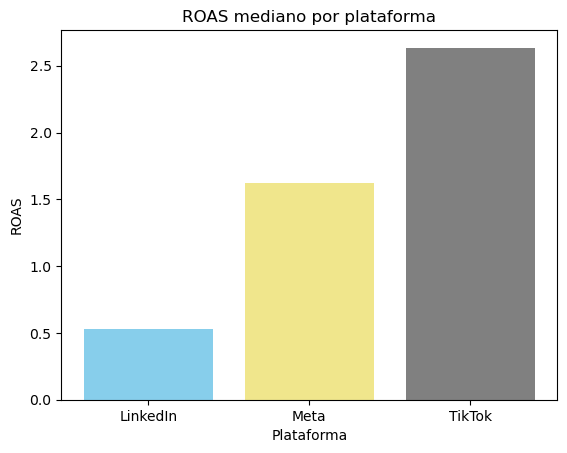

In [35]:
roas_plataforma = (df.groupby("platform")["roas"].median().sort_values())
#ordena o valor do maior pro menor, calculando a mediana do roas separado por plataforma

plt.bar(roas_plataforma.index, roas_plataforma.values, color = ['skyblue', 'khaki', 'gray']) #plataforma, medianas
plt.title("ROAS mediano por plataforma")
plt.xlabel("Plataforma")
plt.ylabel("ROAS")
plt.xticks()
plt.show()

As campanhas do TikTok tiveram o maior ROAS mediano nessa base, seguidas pelas da Meta e do LinkedIn. Mas isso não prova que anunciar no TikTok sempre gera mais retorno. As campanhas de lá podem ter públicos, produtos ou objetivos diferentes, e essas diferenças também podem explicar o resultado.

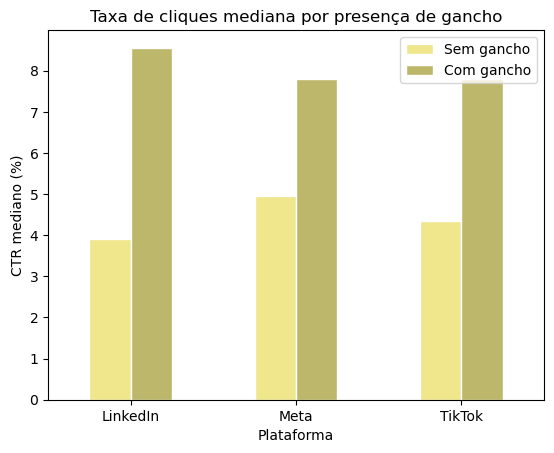

In [47]:
ctr_gancho = (df.groupby(["platform", "has_hook"])["ctr"].median().unstack().reindex(columns=[False, True])*100)
#calcula o ctr mediano com e sem gancho, transformando os valores de "has_hook" em colunas e as plataformas nas linhas
#depois multiplica por 100 para para porcentagens

ctr_gancho.columns = ["Sem gancho", "Com gancho"]
ctr_gancho.plot(kind="bar",color=['khaki', 'darkkhaki'],edgecolor='white')
plt.title("Taxa de cliques mediana por presença de gancho")
plt.xlabel("Plataforma")
plt.ylabel("CTR mediano (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

Vídeos com gancho apresentam maior CTR mediano nas três plataformas. Esse padrão sugere priorizar testes com gancho nos primeiros três segundos, mas não permite afirmar que o gancho, por si só, seja responsável pelo maior CTR.

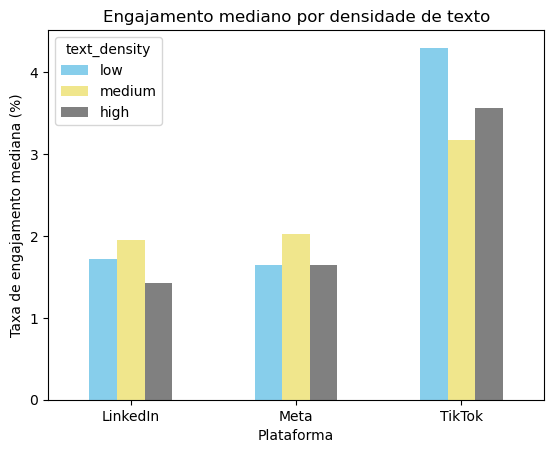

In [56]:
engajamento_texto = (df.groupby(["platform", "text_density"])["engagement_rate"].median().unstack().reindex(columns=["low", "medium", "high"])*100)
#taxa de engajamento mediana para cada nível de qtde de texto, separamente por plataforma

engajamento_texto.plot(kind="bar",color=['skyblue', 'khaki', 'gray'])

plt.title("Engajamento mediano por densidade de texto")
plt.xlabel("Plataforma")
plt.ylabel("Taxa de engajamento mediana (%)")
plt.xticks(rotation=0)
plt.show()

A densidade média de texto apresenta maior engajamento mediano no LinkedIn e na Meta, enquanto a densidade baixa se destaca no TikTok. Ou seja, o volume ideal de texto varia de acordo com o ecossistema de cada rede social e o comportamento nativo dos seus usuários e sugere adaptar os testes de quantidade de texto à plataforma.

<a id="parte-2-modelagem"></a>
## Parte 2 — Modelagem
O objetivo é prever o Klike Score com base nas características de cada criativo e do contexto informado disponíveis antes da publicação. Métricas de desempenho não serão utilizadas nessa análise, pois só são disponíveis após a veiculação da campanha.

## Parte 2 — Modelagem

### 2.1. Feature engineering e seleção das variáveis
Serão selecionadas as variáveis qualitativas e quantitativas, que já foram utilizadas na análise do desempenho de cada criativo, e os contextos específicos de cada campanha, ou seja, plataforma, categoria, objetivo, público alvo e se é uma campanha de redirecionamento ou não, representados por `platform`, `category`, `objective`, `target_audience_age` e `is_retargeting`.

In [17]:
contexto = ["platform", "category", "objective", "target_audience_age", "is_retargeting"]
variaveis_modelo = contexto + caracteristicas_numericas + caracteristicas_qualitativas

x = df[variaveis_modelo].copy() #cria-se uma cópia da tabela original para a modelagem
fx = df['klike_score'].copy()

### 2.2. Separação entre treino e teste

In [18]:
from sklearn.model_selection import train_test_split #separa os dados em treino e teste

x_treino, x_teste, fx_treino, fx_teste = train_test_split(x, fx, test_size = 0.2, random_state=0)
#divide 20% do total (100 campanhas) para teste e o restante vira treino
#random_state fixa a "trilha" que o computador irá seguir para que a divisão de teste e treino seja sempre a mesma com os mesmos dados

print("Campanhas para teste: ", len(x_teste))
print("Campanhas para treino: ", len(x_treino))

Campanhas para teste:  100
Campanhas para treino:  400


As células com variáveis numéricas faltantes serão preenchidas com a mediana do treino. O teste deve representar campanhas novas, que o modelo ainda não conhece. Assim, todas as regras aprendidas com os dados vêm do treino. Nas variáveis categóricas, será utilizada a categoria "não informado" 

### 2.3. Preparação das variáveis

In [19]:
x_treino_preparado = x_treino.copy() 
x_teste_preparado = x_teste.copy()

for caracteristica in caracteristicas_numericas:
    mediana = x_treino[caracteristica].median()
    x_treino_preparado[caracteristica] = (x_treino_preparado[caracteristica].fillna(mediana)) #preenche os valores faltantes de treino com a mediana
    x_teste_preparado[caracteristica] = (x_teste_preparado[caracteristica].fillna(mediana)) #preenche os valores faltantes de teste com a mediana
    #válido ressaltar que é a mediana do TREINO nas duas --> são os valores ja conhecidos

#legenda é a única variável categórica com valores faltantes entre as entradas, assim, vamos preencher as colunas vazias com "não informado"
x_treino_preparado["has_subtitle"] = x_treino_preparado["has_subtitle"].fillna("não informado")
x_teste_preparado["has_subtitle"] = x_teste_preparado["has_subtitle"].fillna("não informado")

categoricas = contexto + caracteristicas_qualitativas

x_treino_preparado = pd.get_dummies(x_treino_preparado, columns=categoricas, dtype=int)
#transforma os valores das colunas em valores de 1(sim) e 0(não) para cada uma delas
#ex: coluna "platform" == "Meta" --> platform_LinkedIn == 0, platform_Meta == 1, platform_TikTok == 0
x_teste_preparado = pd.get_dummies(x_teste_preparado, columns=categoricas, dtype=int)

display(x_treino_preparado)


,video_duration_s,music_voice_ratio,platform_LinkedIn,platform_Meta,platform_TikTok,category_App Install,category_Branding,category_E-commerce,category_Lead Gen,category_SaaS,...,has_subtitle_False,has_subtitle_True,has_subtitle_não informado,has_cta_False,has_cta_True,has_face_False,has_face_True,text_density_high,text_density_low,text_density_medium
107,9.0,0.83,0,0,1,0,0,0,0,1,...,1,0,0,0,1,0,1,0,0,1
336,20.0,0.26,1,0,0,0,0,0,1,0,...,1,0,0,0,1,0,1,0,1,0
71,16.0,0.74,0,1,0,0,1,0,0,0,...,0,1,0,0,1,0,1,0,0,1
474,10.0,0.32,0,0,1,0,0,1,0,0,...,1,0,0,1,0,0,1,0,0,1
6,16.0,0.33,0,1,0,0,0,0,1,0,...,0,1,0,1,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
323,27.0,0.41,0,1,0,0,0,0,0,1,...,0,1,0,0,1,1,0,0,1,0
192,11.0,0.38,1,0,0,1,0,0,0,0,...,0,1,0,0,1,1,0,0,0,1
117,5.0,0.69,0,1,0,0,0,1,0,0,...,1,0,0,0,1,0,1,0,1,0
47,15.0,0.73,0,0,1,0,1,0,0,0,...,0,1,0,0,1,0,1,1,0,0


### 2.4. Modelo e justificativa
Será treinado um modelo de regressão linear para prever o Klike Score. Seu desempenho será comparado a uma referência simples que prevê, para todas as campanhas, a média e a mediana dos scores do treino. A regressão linear foi escolhida como modelo inicial por sua simplicidade e facilidade de interpretação. Seu desempenho será avaliado para verificar em que medida uma combinação linear das características consegue prever o Klike Score

In [20]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression() #cria o modelo 
modelo.fit(x_treino_preparado, fx_treino) #faz o modelo aprender com as características e scores do treino
previsoes = modelo.predict(x_teste_preparado) #usa as características do teste para prever os scores, sem receber as respostas reais

#comparando com o valor real dos scores:
comparacao = pd.DataFrame({"score real":fx_teste,"score previsto":previsoes})
comparacao['erro absoluto'] = abs(comparacao['score real'] - comparacao['score previsto'])
display(comparacao.head())

mae_modelo = comparacao['erro absoluto'].mean()

media_treino = fx_treino.mean()
mediana_treino = fx_treino.median()
mae_media = abs(fx_teste - media_treino).mean()
mae_mediana = abs(fx_teste - mediana_treino).mean()

print("MAE pela média:", mae_media)
print("MAE pela mediana:", mae_mediana)
print("MAE da regressão linear:", mae_modelo)

,score real,score previsto,erro absoluto
90,68.5,65.051045,3.448955
254,73.2,63.912309,9.287691
283,45.5,47.425846,1.925846
445,64.8,74.541296,9.741296
461,44.0,46.318114,2.318114


MAE pela média: 12.25506
MAE pela mediana: 12.232999999999999
MAE da regressão linear: 6.1526749832305345


No conjunto de teste, a regressão linear apresentou erro absoluto médio de 6.15 pontos do Klike Score, enquanto as referências baseadas na média e na mediana do treino apresentaram erros de 12,26 e 12,23 pontos, respectivamente. Isso representa uma redução de aproximadamente 50% no MAE em relação às duas referências. Portanto, nesta divisão dos dados, utilizar as características dos criativos e o contexto das campanhas produziu previsões melhores do que atribuir um único valor, seja ele a média ou a mediana do treino, a todas as campanhas.

### 2.5. Avaliação e validação cruzada

A validação cruzada em cinco divisões do conjunto de treino apresentou MAE médio de 7,03 pontos, com resultados entre 6,70 e 7,20 pontos. A variação relativamente pequena entre as rodadas sugere desempenho consistente nas divisões avaliadas. No teste separado, o MAE foi de 6,15 pontos, inferior à média da validação cruzada.

RMSE: 7.637065529183086


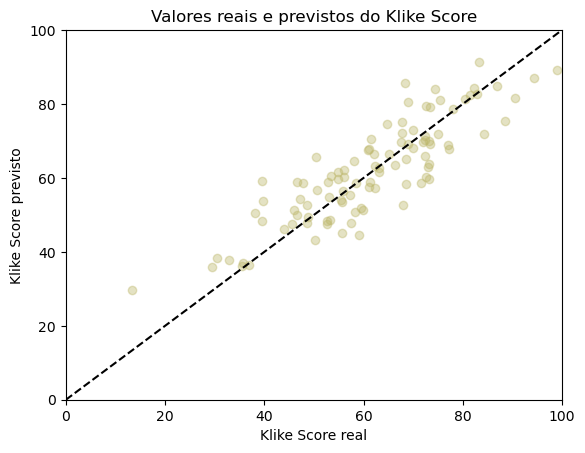

In [61]:
rmse = np.sqrt(((comparacao["score real"] - comparacao["score previsto"]) ** 2).mean())
#Raiz do Erro Quadrático Médio (root mean square error)
#subtrai o valor previsto do valor real para obter os erros individuais
#eleva ao quadrado para evitar erros de se anularem, calcula a média e tira a raíz quadrada para trazer de volta à unidade de medida inicial

print("RMSE:", rmse)

plt.scatter(fx_teste, previsoes, alpha=0.4, color='darkkhaki')
plt.plot([0,100], [0,100], "--", color='black')
plt.xlabel("Klike Score real")
plt.ylabel("Klike Score previsto")
plt.title("Valores reais e previstos do Klike Score")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.show()

A validação cruzada em cinco divisões do conjunto de treino apresentou MAE médio de 6,81 pontos, com resultados entre 6,30 e 7,20 pontos. A variação relativamente pequena entre as rodadas e a proximidade com o MAE do teste separado (6,82) sugerem desempenho consistente nas divisões avaliadas.

In [66]:
from sklearn.model_selection import KFold

divisoes = KFold(n_splits=5, shuffle=True, random_state=0)
#criar uma  divisão dos dados em 5 partes, embaralhando as linhas antes de dividir e repetindo as mesmas divisões ao executar novamente
maes = [] #cria lista vazia para guardar o MAE de cada rodada

for indices_treino, indices_validacao in divisoes.split(x_treino): #fazer 5 rodadas, em cada uma usar 4 partes p/ treino e 1 p/ validação
    #selecionar as campanhas dessa rodada pela posição das linhas
    entradas_treino = x_treino.iloc[indices_treino].copy()
    entradas_validacao = x_treino.iloc[indices_validacao].copy()
    #usamos .copy() para fazer alterações numa cópia independente, sem alterar os dados originais.  
    scores_treino = fx_treino.iloc[indices_treino]
    scores_validacao = fx_treino.iloc[indices_validacao]
    #não precisamos alterar os scores, logo não usamos .copy().

    #aprender as medianas apenas no treino desta rodada
    for coluna in caracteristicas_numericas: #percorrer cada coluna para tratar os valores faltantes
        mediana = entradas_treino[coluna].median() 
        #preencher os valores faltantes com essa mediana
        entradas_treino[coluna] = entradas_treino[coluna].fillna(mediana) 
        entradas_validacao[coluna] = entradas_validacao[coluna].fillna(mediana)
    
    #preencher os valores de "has_subtitle" com "não informado"
    entradas_treino["has_subtitle"] = (entradas_treino["has_subtitle"].fillna("não informado")) 
    entradas_validacao["has_subtitle"] = (entradas_validacao["has_subtitle"].fillna("não informado")) 

    #transformar as categoriass de treino e validção em categóricas
    entradas_treino = pd.get_dummies(entradas_treino, columns=categoricas, dtype=int) 
    entradas_validacao = pd.get_dummies(entradas_validacao, columns=categoricas, dtype=int)
    #deixar validação com mesmas colunas e ordem do treino: colunas ausentes são criadas com 0 e colunas extras são removidas
    entradas_validacao = entradas_validacao.reindex(columns=entradas_treino.columns, fill_value=0) 

    #criar novo modelo de regressão linear e treinar, relacionando as entradas com os scores das campanhas de validação
    modelo_rodada = LinearRegression()
    modelo_rodada.fit(entradas_treino, scores_treino)
    
    previsoes_rodada = modelo_rodada.predict(entradas_validacao) #utilizar o modelo para prever os scores
    mae_rodada = abs(scores_validacao - previsoes_rodada).mean() #calcular o MAE (média das diferenças absolutas) entre scores reais e previstos
    maes.append(mae_rodada) #guardar o mae dessa rodada na lista 

for rodada, mae in enumerate(maes, start=1): #enumerar as MAEs começando da rodada 1
    print(f"MAE da rodada {rodada}: {mae:.2f}")

print("MAE médio da validação cruzada:", np.mean(maes)) #média dos 5 MAEs

MAE da rodada 1: 7.04
MAE da rodada 2: 7.16
MAE da rodada 3: 6.70
MAE da rodada 4: 7.20
MAE da rodada 5: 7.04
MAE médio da validação cruzada: 7.0285811017211985


### 2.6. Feature importance e interpretação de negócio
Entre as quatro características binárias analisadas, a presença de gancho apresenta a maior diferença positiva no Klike Score previsto, seguida por rosto, legenda e CTA. Essas diferenças representam associações aprendidas pela regressão, mantendo as demais entradas constantes, e não garantem ganhos reais após a edição do vídeo.

In [68]:
pesos = pd.Series(modelo.coef_,index=x_treino_preparado.columns) #Series que associa cada coeficiente do modelo ao nome da coluna correspondente

efeitos = {} #dicionario para diferenças calculadas

for caracteristica in ["has_hook", "has_subtitle", "has_cta", "has_face"]: 
    efeitos[caracteristica] = (pesos[caracteristica + "_True"] - pesos[caracteristica + "_False"])
    #subtrair coeficiente False de True -> o quanto a previsão muda ao ser inserida tal característica

efeitos = pd.Series(efeitos) #transforma o dicionário em uma Series

display(efeitos.sort_values(ascending=False)) #mostra os c mais diferença primeiro

has_hook        17.491388
has_face        11.848892
has_subtitle     7.984298
has_cta          7.719618
dtype: float64

<a id="parte-3-recommendations-engine"></a>
## Parte 3 — Recommendations Engine

O protótipo simula mudanças nas características do criativo e comparaos Klike Scores previstos. As sugestões representam hipóteses para teste, sem garantia de melhoria real.

### 3.1. Funcionamento e critérios

In [69]:
video = x_teste.iloc[[0]].copy() #selecionar o 1° vídeo do conjunto de testes
display(video) #mostrar as características do vídeo escolhido

def prever_score(video): #função que recebe um DataFrame e devolve seu score previsto
    preparado = video.copy() #cria cópia para preparar os dados sem alterar o vídeo recebido

    for coluna in caracteristicas_numericas: 
        mediana = x_treino[coluna].median()
        preparado[coluna] = preparado[coluna].fillna(mediana) #preencher valores faltantes com mediana

    #aplicar função a cada valor da coluna "has_subtitle" --> se estiver faltando, substituir por "não informado", se existir, retornar valor 
    preparado["has_subtitle"] = preparado["has_subtitle"].map(lambda valor: "não informado" if pd.isna(valor) else valor)
    preparado = pd.get_dummies(preparado, columns=categoricas, dtype=int) #transformar em colunas de 0 e 1
    preparado = preparado.reindex(columns=x_treino_preparado.columns, fill_value=0) #colocar na mesma ordem e com os mesmos nomes
    #criar com 0 as colunas faltantes e remover as extras

    return modelo.predict(preparado)[0] #prever o score e devolver o primeiro valor

score_atual = prever_score(video) # calcular o score previsto para o video com suas características atuais
sugestoes = []

for caracteristica in ["has_hook", "has_face", "has_cta"]: #características que queremos testar
    if video[caracteristica].iloc[0] == False: #verificar se ele nao possui a característica
        video_alterado = video.copy() #se não tiver, criar uma cópia
        video_alterado[caracteristica] = True #modificar para True a cópia
        novo_score = prever_score(video_alterado) #medir o score dessa previsão
        sugestoes.append({"mudanca": caracteristica,"score_atual_previsto": score_atual,"score_apos_mudanca": novo_score,
                          "ganho_previsto": novo_score - score_atual}) #guarda a mudança, os 2 scores e a diferença entre eles

if sugestoes: #verificar se possui sugestoes
    recomendacoes = pd.DataFrame(sugestoes) #se sim, transformar em uma tabela
    display(recomendacoes.sort_values("ganho_previsto", ascending=False)) #ordenar pelo maior gancho previsto
else:
    print("O vídeo já possui gancho, rosto e CTA.") #se não, avisar que já possui todas as características

,platform,category,objective,target_audience_age,is_retargeting,video_duration_s,music_voice_ratio,has_hook,format,has_subtitle,has_cta,has_face,text_density
90,Meta,E-commerce,traffic,18-24,False,43.0,0.04,True,quadrado,False,True,False,medium


,mudanca,score_atual_previsto,score_apos_mudanca,ganho_previsto
0,has_face,65.051045,76.899937,11.848892


### 3.2. Implementação e demonstração
Comparar os scores reais de campanhas da mesma plataforma e categoria do vídeo, para verificar se os dados apoiam a mudança sugerida.

In [78]:
def evidencia_contextual(video, coluna, valor_atual, valor_novo):
    plataforma = video["platform"].iloc[0] #obter a plataforma do video
    categoria = video["category"].iloc[0] #obter a categoria do video

    base = df.loc[x_treino.index] #selecionar no df apenas as colunas do treino

    # filtrar campanhas da mesma plataforma E categoria
    semelhantes = base.loc[(base["platform"] == plataforma) & (base["category"] == categoria)] 
    #selecionar os scores da campanha com a condição atual, dropna() remove os scores faltantes
    grupo_atual = semelhantes.loc[semelhantes[coluna] == valor_atual, "klike_score"].dropna()
    #selecionar os scores da campanha com a alternativa proposta
    grupo_novo = semelhantes.loc[semelhantes[coluna] == valor_novo, "klike_score"].dropna()

    #contar quantas campanhas com score disponível existem em cada grupo
    n_atual = len(grupo_atual)
    n_novo = len(grupo_novo)

    diferenca = grupo_novo.median() - grupo_atual.median()

    if diferenca < 0:
        aviso = "Evidência conflitante." #se a alternativa tiver mediana menor, definir esse aviso
    elif diferenca == 0:
        aviso = "Sem diferença entre as medianas." #medianas iguais
    else:
        aviso = "Evidência consistentes." #se a alternativa tiver mediana maior

    return (f"{aviso} "
        f"{plataforma} / {categoria}: diferença observada de "
        f"{diferenca:+.2f} pontos"
        f"({n_atual} campanhas na condição atual e "
        f"{n_novo} na alternativa). ")

In [81]:
def recomendar(video): #testa mudanças no vídeo, guarda as que aumentam o score previsto e apresenta a evidência contextual de cada uma.
    score_atual = prever_score(video)
    sugestoes = []

    mudancas = { #associar cada coluna com a descrição da mudança que será sugerida
        "has_hook": "Adicionar gancho",
        "has_face": "Adicionar rosto",
        "has_cta": "Adicionar chamada para ação",
        "has_subtitle": "Adicionar legenda"}

    for coluna, descricao in mudancas.items():
        valor_atual = video[coluna].iloc[0] #obter o valor dessas características no video

        if pd.notna(valor_atual) and valor_atual == False: #testar apenas se o valor estiver preenchido e se for False
            video_alterado = video.copy()
            video_alterado[coluna] = True #simular a inclusão da característica na cópia

            novo_score = prever_score(video_alterado) #prever o score após a mudança
            ganho = novo_score - score_atual

            if ganho > 0: #guardar a sugestao apenas se ganho for positivo
                sugestoes.append({
                    "sugestao": descricao,
                    "score_atual_previsto": score_atual,
                    "score_apos_mudanca": novo_score,
                    "ganho_previsto": ganho, "evidencia_contextual": evidencia_contextual(video, coluna, valor_atual, True)})
                    #comparar scores reais de campanhas

    # definir mudanças de formato e densidade de texto
    alternativas = {"format": ["vertical", "horizontal", "quadrado"], "text_density": ["low", "medium", "high"]}
    #obter a plataforma
    plataforma = video["platform"].iloc[0]

    for coluna, opcoes in alternativas.items(): #percorrer cada coluna e sua lista de alternativas
        valor_atual = video[coluna].iloc[0] #obter a opção que o vídeo utiliza atualmente

        for opcao in opcoes: #percorrer as alternativas dessa coluna
            if opcao == valor_atual:
                continue #se for igual à opção atual, pular as próximas linhas

            if coluna == "format": #verificação extra para mudanças de formato
                formatos_observados = x_treino.loc[x_treino["platform"] == plataforma, "format"].values
                #selecionar os formatos presentes no treino em campanhas da mesma plataforma do vídeo, .values() obtém esses valores em um array

                if opcao not in formatos_observados: #pular o formato se ele não apareceu nessa plataforma de treino
                    continue

            video_alterado = video.copy() #criar outra cópia
            video_alterado[coluna] = opcao #substituir o formato ou a densidade de texto pela opção testada

            novo_score = prever_score(video_alterado) #prever o score com essa alteração
            ganho = novo_score - score_atual #calcular a diferença em relação à previsão inicial

            if ganho > 0: #guardar apenas mudanças com ganho previsto positivo
                sugestoes.append({ 
                    "sugestao": f"Alterar {coluna} de {valor_atual} para {opcao}",
                    "score_atual_previsto": score_atual,
                    "score_apos_mudanca": novo_score,
                    "ganho_previsto": ganho, "evidencia_contextual": evidencia_contextual(video, coluna, valor_atual, opcao)})
                    #comparar os scores observados nas duas condições, dentro da mesma plataforma e categoria

    resultado = pd.DataFrame(sugestoes, columns=["sugestao","score_atual_previsto","score_apos_mudanca","ganho_previsto","evidencia_contextual"])
    return resultado.sort_values("ganho_previsto", ascending=False)

In [87]:
video = x_teste.iloc[[0]].copy() #selecionar o primeiro vídeo do teste, mantendo o formato de DataFrame
recomendacoes = recomendar(video) #executar a função e guardar a tabela de recomendações

if recomendacoes.empty: #verificar se a tabela está vazia, ou seja, sem recomendações
    print("Nenhuma melhoria prevista nas alterações avaliadas.")
else: #se houver recomendações, mostrar os resultados
    display(recomendacoes.drop(columns="evidencia_contextual").round(2))

    for _, linha in recomendacoes.iterrows():
        print(linha["sugestao"])
        print(linha["evidencia_contextual"])
        print()

,sugestao,score_atual_previsto,score_apos_mudanca,ganho_previsto
0,Adicionar rosto,65.05,76.90,11.85
1,Adicionar legenda,65.05,73.04,7.98
2,Alterar format de quadrado para vertical,65.05,66.38,1.33


Adicionar rosto
Evidência consistentes. Meta / E-commerce: diferença observada de +12.55 pontos(32 campanhas na condição atual e 27 na alternativa). 

Adicionar legenda
Evidência consistentes. Meta / E-commerce: diferença observada de +15.20 pontos(19 campanhas na condição atual e 32 na alternativa). 

Alterar format de quadrado para vertical
Evidência conflitante. Meta / E-commerce: diferença observada de -5.60 pontos(18 campanhas na condição atual e 25 na alternativa). 



No exemplo avaliado, adicionar rosto apresentou o maior ganho previsto, seguido pela inclusão de legenda. As sugestões representam hipóteses para teste e não garantem melhoria real no desempenho.

### 3.3. Limitações

A base contém 500 campanhas, com valores faltantes, grupos de tamanhos
diferentes e inconsistências entre algumas métricas. Essas condições
limitam a generalização dos resultados.

As associações observadas não demonstram causalidade. Portanto, um
ganho previsto pelo recomendador não garante que editar o vídeo
produzirá esse aumento no score real ou no retorno financeiro.

A regressão utilizada considera contribuições aditivas e não inclui
interações explícitas entre plataforma e características do vídeo.
Assim, a diferença prevista ao adicionar gancho, por exemplo, é a
mesma entre plataformas, embora a análise exploratória indique
padrões que podem variar conforme o contexto.